# fibonacci_boundary_distance — 小規模実行例

**動作確認用設定。openは単元候補の自明な参照結果で、境界効果の研究結果ではありません。**

## 1. 研究目的
有限Fibonacci列における消失領域と端との距離を調べる、**open-boundary補助解析**です。
連続消失とwindow内の任意消失を比較し、左右の配置、中央との差、観測距離格子上のしきい値を記録します。

**既存の有限ring QECCには物理的な端がありません。** ringでwindowを動かす計算は平行移動不変性の検証です。
本Notebookの `geometry="open"` と `geometry="ring"` は別モデルとして保存・描画し、
`fibonacci_finite_size_scaling` の結果を上書きしません。

### 先に確認する重要事項
以前のNotebookと同じrecoverabilityは、**各論理クラス内部で**残存bitが候補列を一意に決める性質です。
固定seedから得られる1本ずつのopen列だけを候補にすると、候補集合は単元集合となり、
**全消失を含めてrecoverabilityは常にTrue**です。これは境界効果の測定になりません。

既定のopenモードはこの固定原点の古典的参照モデルを明示的に実装します。
非自明な境界依存を調べるには、物理的に意図する**非周期的な候補集合**を下のfactoryで指定してください。
未定義の量子状態や巡回軌道をopen chainへ自動的に導入しません。

## 2. 引き継ぐ定義とopenモデルの位置づけ
前成果物 `fibonacci_recoverability_kl` の `recoverability_kl.py` と `legacy_functions.py` を変更せず同梱しています。
出典とSHA256は `source_manifest.json` に保存しています。

- inflation: $1\mapsto10,\ 0\mapsto1$。$N=|F_i^{(n)}|$ を計算し、直接入力しません。
- 既存seed: `000111 / 010101`、$k_0=k_1=3$。各実行でseed条件を再検証します。
- ring: 異なる巡回列を重複なく集めた $O_i$ に対し、$|\Psi_i\rangle=|O_i|^{-1/2}\sum_{x\in O_i}|x\rangle$。
- open: 座標 $0,\ldots,N-1$ を固定し、最後と最初を接続しません。候補 $C_i$ は明示的に与えます。

消失集合を $E$、残存領域を $\bar E$ とすると、既存の古典指標は
$$\mathrm{rec}_i(E)\iff [x_{\bar E}=y_{\bar E}\Rightarrow x=y\quad (x,y\in C_i)],\qquad
\mathrm{rec}(E)=\mathrm{rec}_0(E)\land\mathrm{rec}_1(E).$$
これは論理ラベル0/1の識別可能性とは別の条件です。単に $F_0$ と $F_1$ を区別できるかへ定義を置き換えません。

## 3. 手動入力
================================
ここはユーザーが手動入力する
================================

既存Notebookのseedを初期値にしています。`N` は入力しません。
本番設定は計算量が大きくなるため、初回は準備・sanity check・benchmarkまで実行します。
見積りを確認した後、`RUN_FULL_ANALYSIS=True` にすると本計算を実行します。

In [1]:
# ==============================
# ユーザーが手動入力する項目
# ==============================
SEED_0 = "000111"
SEED_1 = "010101"
PAIR_ID = "L06_W03_P0001"
INFLATION_LIST = [1, 2, 3, 4]
WINDOW_SIZE_LIST = [8]
BOUNDARY_DISTANCE_LIST = [0, 2, 5, 10]
ERASURE_SIZE_LIST = [1, 2, 4]
MAX_EXACT_PATTERNS = 50
NUM_RANDOM_SAMPLES = 80
RANDOM_SEED = 42
EPSILON_BOUNDARY = 0.01
SAVE_RESULTS = True
SAVE_FIGURES = True

# 補助設定
BOUNDARY_SIDES = ["left", "right"]
INCLUDE_CENTER = True
BOUNDARY_FRACTION_LIST = [0.1]  # 例: [0.05, 0.1, 0.2]; sites走査とは別集計
OUTPUT_DIR = "example_results"
FIGURES_DIR = "example_figures"
DETAIL_MEMORY_LIMIT = 2000  # CSVは全行保存、画面保持のみ制限
BENCHMARK_PATTERNS = 100  # 100～1000。候補が少なければ繰り返して測定
RUN_FULL_ANALYSIS = True
MAX_ESTIMATED_SECONDS = 600  # 必要なら見積り確認後に調整

## 4. open chainの候補集合と、任意のKL拡張
既定設定は $C_i=\{F_i^{(n)}\}$ の古典モデルです。これは要求された固定原点open列の最小限の参照実装で、
**非自明な境界モデルの提案ではありません**。率1・$B_\star=0$ は定義から生じます。

意味のあるopen解析では `OPEN_CANDIDATE_FACTORY(F0_n, F1_n, n)` が、同じ長さ $N$ の異なるbit列の集合
`(C0, C1)` を返すように実装し、モデル名・候補集合の由来を記述してください。
候補は各$n$で一度だけ生成し、$B,W,m$によって変更しません。
周期的な候補集合を指定した場合、その統計から物理的な端の効果を自動的に主張できません。

open KLを有効にできるのは、次の状態を明示的に採用する場合だけです。
$$|\Psi_i^{\mathrm{open}}\rangle=|C_i|^{-1/2}\sum_{x\in C_i}|x\rangle,\quad C_0\cap C_1=\varnothing.$$
全振幅は正・等振幅です。以下の宣言と、その状態が意図するopenモデルに適切である理由を記入してください。
任意の複素振幅・非直交状態をこの設定で扱うことはできません。既定ではKLは計算せずNAとして保存します。

In [2]:
OPEN_MODEL_ID = "anchored_singleton"
OPEN_MODEL_DESCRIPTION = "Fixed-origin open words C_i={F_i^(n)}; trivial within-class classical reference."
OPEN_CANDIDATE_FACTORY = None
ENABLE_OPEN_KL = False
OPEN_QUANTUM_STATE_DEFINITION = None

# 非自明な候補集合が定義済みの場合のみ差し替える：
# def my_open_candidates(F0_n, F1_n, n):
#     return C0, C1  # 研究で定義した、長さNの候補列を返す
# OPEN_CANDIDATE_FACTORY = my_open_candidates
# OPEN_MODEL_ID = "your_documented_open_model"
# OPEN_MODEL_DESCRIPTION = "候補集合、原点の不確かさ、端での制約の定義を記す"
#
# 上記の等振幅量子状態を明示的に採用する場合だけ：
# ENABLE_OPEN_KL = True
# OPEN_QUANTUM_STATE_DEFINITION = {
#     "family": "equal_positive_uniform_support",
#     "description": "この状態とopen boundaryを採用する研究上の理由を記す",
# }

## 5. 準備
Python 3.10以上、`numpy / pandas / matplotlib / jupyterlab / nbformat / nbclient` を使用します。
このNotebookを同梱のPythonファイルと同じフォルダで開いてください。

In [3]:
from pathlib import Path
import json
import time
import warnings
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import boundary_models as models
import boundary_distance as bd
import boundary_reporting as reporting

pd.set_option("display.max_columns", 30)
cfg = bd.Config(
    seed_0=SEED_0, seed_1=SEED_1, pair_id=PAIR_ID,
    inflation_list=tuple(INFLATION_LIST), window_size_list=tuple(WINDOW_SIZE_LIST),
    boundary_distance_list=tuple(BOUNDARY_DISTANCE_LIST), erasure_size_list=tuple(ERASURE_SIZE_LIST),
    max_exact_patterns=MAX_EXACT_PATTERNS, num_random_samples=NUM_RANDOM_SAMPLES,
    random_seed=RANDOM_SEED, epsilon_boundary=EPSILON_BOUNDARY,
    boundary_sides=tuple(BOUNDARY_SIDES), include_center=INCLUDE_CENTER,
    boundary_fraction_list=tuple(BOUNDARY_FRACTION_LIST),
    save_results=SAVE_RESULTS, save_figures=SAVE_FIGURES,
    output_dir=OUTPUT_DIR, figures_dir=FIGURES_DIR, detail_memory_limit=DETAIL_MEMORY_LIMIT,
    open_model_id=OPEN_MODEL_ID, open_model_description=OPEN_MODEL_DESCRIPTION)

## 6. logical seed検証・inflation・N一覧
同じ$k_0,k_1$、巡回非同値、両方向の1回の隣接01/10交換で相手の巡回同値類に移らないことを確認します。
seedの条件には既存研究と同じ周期的な隣接関係を使います。open上のwindow配置とは独立の検証です。
以下の条件だけから、原論文の追加条件を含む訂正保証を主張することはしません。

In [4]:
display(pd.DataFrame([models.validate_pair(SEED_0, SEED_1)]))
prepared = bd.prepare(cfg, candidate_factory=OPEN_CANDIDATE_FACTORY,
    quantum_state_definition=OPEN_QUANTUM_STATE_DEFINITION, enable_open_kl=ENABLE_OPEN_KL)
size_df = prepared.size_table
display(size_df)
open_model_df = pd.DataFrame([prepared.models[(n, "open")].metadata for n in INFLATION_LIST])
display(open_model_df[["inflation_n", "N", "model_id", "support_size_0", "support_size_1", "open_kl_enabled"]])
if open_model_df.open_support_is_singleton.all():
    display(Markdown("**参照モード：候補が各1本なのでR_rec=1。境界効果の有無は判定できません。**"))
if ENABLE_OPEN_KL:
    display(Markdown("**採用したopen量子状態の定義**"))
    display(OPEN_QUANTUM_STATE_DEFINITION)
    print(models.UNIFORM_STATE_FORMULA)

/Users/ideryuito/Documents/Codex/2026-10-06/files-pasted-by-the-user-fibonacci-5/outputs/fibonacci_boundary_distance/boundary_distance.py:180: UserWarning: B=2, W=8, N=9: B+W>N; skipping window
  windows.extend(dict(inflation_n=n, **r) for r in windows_for(N, W, cfg))
/Users/ideryuito/Documents/Codex/2026-10-06/files-pasted-by-the-user-fibonacci-5/outputs/fibonacci_boundary_distance/boundary_distance.py:180: UserWarning: B=5, W=8, N=9: B+W>N; skipping window
  windows.extend(dict(inflation_n=n, **r) for r in windows_for(N, W, cfg))
/Users/ideryuito/Documents/Codex/2026-10-06/files-pasted-by-the-user-fibonacci-5/outputs/fibonacci_boundary_distance/boundary_distance.py:180: UserWarning: B=10, W=8, N=9: B+W>N; skipping window
  windows.extend(dict(inflation_n=n, **r) for r in windows_for(N, W, cfg))
/Users/ideryuito/Documents/Codex/2026-10-06/files-pasted-by-the-user-fibonacci-5/outputs/fibonacci_boundary_distance/boundary_distance.py:180: UserWarning: B=10, W=8, N=15: B+W>N; skipping win

,seed_length,k0,k1,adjacent_swap_valid
0,6,3,3,True


,inflation_n,N,k0,k1,inflated_count_0,inflated_count_1
0,1,9,3,3,3,6
1,2,15,3,3,6,9
2,3,24,3,3,9,15
3,4,39,3,3,15,24


,inflation_n,N,model_id,support_size_0,support_size_1,open_kl_enabled
0,1,9,anchored_singleton,1,1,False
1,2,15,anchored_singleton,1,1,False
2,3,24,anchored_singleton,1,1,False
3,4,39,anchored_singleton,1,1,False


**参照モード：候補が各1本なのでR_rec=1。境界効果の有無は判定できません。**

## 7. window配置・左右・中央
左配置は `start=B`、右配置は `start=N-W-B`、中央は $\lfloor(N-W)/2\rfloor$ です。
`end=start+W-1`、左余白は `start`、右余白は `N-start-W`。
$B+W>N$ または $m>W$ は警告してskipします。openではmoduloによる巻き戻しをしません。

$B$を増やして中央を通り過ぎると反対側の端へ近づくので、両余白と最小余白を保存します。
$B_\star$の評価は指定した側が最寄りの端である点だけに限定します。
`fraction`では $B=\lfloor fN\rfloor$、要求した$f$と実現した$B/N$を両方記録します。

In [5]:
window_df = prepared.windows
display(window_df.head(24))
print(f"window placements: {len(window_df)}")

window placements: 36


,inflation_n,N,window_size,boundary_side,distance_mode,boundary_distance,fraction_requested,boundary_fraction_actual,boundary_distance_left,boundary_distance_right,nearest_boundary_distance,window_start,window_end
0,1,9,8,left,sites,0,NaN,0.000000,0,1,0,0,7
1,1,9,8,right,sites,0,NaN,0.000000,1,0,0,1,8
2,1,9,8,left,fraction,0,0.1,0.000000,0,1,0,0,7
3,1,9,8,right,fraction,0,0.1,0.000000,1,0,0,1,8
4,1,9,8,center,center,0,NaN,0.000000,0,1,0,0,7
5,2,15,8,left,sites,0,NaN,0.000000,0,7,0,0,7
6,2,15,8,right,sites,0,NaN,0.000000,7,0,0,7,14
7,2,15,8,left,sites,2,NaN,0.133333,2,5,2,2,9
8,2,15,8,right,sites,2,NaN,0.133333,5,2,2,5,12
9,2,15,8,left,sites,5,NaN,0.333333,5,2,2,5,12


## 8. relative erasure patternを一度生成し、全位置で再利用
連続消失は全開始点を列挙します。任意消失は$inom Wm$が閾値以下なら全探索、上なら一様samplingです。
乱数は `(RANDOM_SEED,W,m)` だけで決めます。同じ$W,m$では、$n$、$B$、左右・中央、geometryにかかわらず
**同じpattern ID・同じ相対消失集合**を使用します。

samplingは独立な復元抽出です。同じ集合が複数回抽出されても独立試行として保持し、試行数とユニーク数を区別します。
左右比較も同じ相対集合を平行移動します。パターンを反転した厳密な鏡映テストとは区別します。

In [6]:
pattern_df = pd.DataFrame([
    dict(window_size=W, erasure_size=m, erasure_type=kind,
         number_of_patterns=len(p.patterns), total_possible=p.total_possible,
         calculation_mode=p.mode, sampling_scheme=p.sampling_scheme, pattern_digest=p.digest)
    for (W,m,kind),p in prepared.patterns.items()])
display(pattern_df)

,window_size,erasure_size,erasure_type,number_of_patterns,total_possible,calculation_mode,sampling_scheme,pattern_digest
0,8,1,contiguous,8,8,exact,enumeration,13e14ddb5e3ad251ece01359b371f8bb6028dff975f4d1...
1,8,1,arbitrary,8,8,exact,enumeration,13e14ddb5e3ad251ece01359b371f8bb6028dff975f4d1...
2,8,2,contiguous,7,7,exact,enumeration,a47f4778812c9996cbf003fb745d4e90ce51e18eb6811e...
3,8,2,arbitrary,28,28,exact,enumeration,efb103c2b90b89be896e19b9523baf9dd1bc567235148e...
4,8,4,contiguous,5,5,exact,enumeration,ca13f16037b36e5f1fb374138861b5ea2aef6c7c9d3ddd...
5,8,4,arbitrary,80,70,sampled,iid_uniform_with_replacement,7604a6c8dd882e7aa82cde2c1b7b9c8783c04262bde316...


## 9. ring translation sanity check
すべての設定条件について一部の相対パターンを実際に移動し、recoverabilityとKLの3条件を照合します。
`N-1→0`をまたぐ消失集合も検証します。ringの$B$は配置のパラメータであり物理的境界距離ではありません。
不一致があれば例外で停止し、cyclic orbit・indexing・window translation・periodic boundary・maskを確認します。
本計算は全位置で直接評価し、全summaryでも位置不変性を再検査します。

In [7]:
sanity_df = bd.ring_sanity_check(prepared, max_patterns=3)
display(sanity_df.groupby(["inflation_n", "N"])["passed"].agg(["count", "all"]))

,,count,all
inflation_n,N,,
1,9,72,True
2,15,144,True
3,24,198,True
4,39,234,True


## 10. benchmark
各$n$, geometry, $W,m$, erasure typeについて100～1000回を計測します。
候補数が少ない場合は同じ候補を繰り返して測ります。各組の最初のwindowを使用します。
見積りはpattern評価部分のみで、CSV・図の保存時間を含みません。候補集合と消失形状によっても時間が変わります。

In [8]:
benchmark_df = bd.benchmark(prepared, count=BENCHMARK_PATTERNS)
display(benchmark_df)
estimated_seconds = float(benchmark_df.estimated_runtime.sum()) if len(benchmark_df) else 0.0
print(f"Estimated evaluation time: {estimated_seconds:.1f} seconds ({estimated_seconds/3600:.2f} hours)")
print("CSV/plot overhead excluded; estimation is not an upper bound.")
if SAVE_RESULTS:
    Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)
    benchmark_df.to_csv(Path(OUTPUT_DIR)/"benchmark.csv", index=False)
    sanity_df.to_csv(Path(OUTPUT_DIR)/"ring_translation_preflight.csv", index=False)
    size_df.to_csv(Path(OUTPUT_DIR)/"inflation_sizes.csv", index=False)
    pattern_df.to_csv(Path(OUTPUT_DIR)/"pattern_plan.csv", index=False)

Estimated evaluation time: 0.1 seconds (0.00 hours)
CSV/plot overhead excluded; estimation is not an upper bound.


,inflation_n,geometry,N,W,B,m,erasure_type,pattern_count,unique_patterns_measured,runtime,time_per_pattern,planned_evaluations,estimated_runtime,calculation_mode,estimate_scope
0,1,open,9,8,0,1,contiguous,100,8,0.000481,0.000005,40,0.000192,exact,evaluation_only_one_placement; excludes IO and...
1,1,ring,9,8,0,1,contiguous,100,8,0.001207,0.000012,40,0.000483,exact,evaluation_only_one_placement; excludes IO and...
2,1,open,9,8,0,1,arbitrary,100,8,0.000450,0.000005,40,0.000180,exact,evaluation_only_one_placement; excludes IO and...
3,1,ring,9,8,0,1,arbitrary,100,8,0.001142,0.000011,40,0.000457,exact,evaluation_only_one_placement; excludes IO and...
4,1,open,9,8,0,2,contiguous,100,7,0.000526,0.000005,35,0.000184,exact,evaluation_only_one_placement; excludes IO and...
5,1,ring,9,8,0,2,contiguous,100,7,0.001239,0.000012,35,0.000433,exact,evaluation_only_one_placement; excludes IO and...
6,1,open,9,8,0,2,arbitrary,100,28,0.000554,0.000006,140,0.000776,exact,evaluation_only_one_placement; excludes IO and...
7,1,ring,9,8,0,2,arbitrary,100,28,0.001241,0.000012,140,0.001737,exact,evaluation_only_one_placement; excludes IO and...
8,1,open,9,8,0,4,contiguous,100,5,0.000587,0.000006,25,0.000147,exact,evaluation_only_one_placement; excludes IO and...
9,1,ring,9,8,0,4,contiguous,100,5,0.001808,0.000018,25,0.000452,exact,evaluation_only_one_placement; excludes IO and...


## 11. classical recoverability・境界距離解析・任意のKL解析
KL判定は既存コードと同じ条件です。
$$\rho_E^{00}=\rho_E^{11}\quad(\mathrm{KL\_diagonal}),\qquad
\rho_E^{01}=0\quad(\mathrm{KL\_offdiagonal}).$$
両方成立するときだけ `KL_correctable=True`。整数カウントの比較を用い、密行列や近似ゼロ判定を使いません。
classical recoverabilityが成立してもKL条件が成立するとは限りません。

open KLが未定義のときは3つともNAです。未計算をFalse・率0へ置き換えません。

In [9]:
result = None
if RUN_FULL_ANALYSIS:
    if estimated_seconds > MAX_ESTIMATED_SECONDS:
        raise RuntimeError(f"見積り {estimated_seconds:.1f}s が上限 {MAX_ESTIMATED_SECONDS}s を超えます。条件または上限を調整してください。")
    last_report = [0.0]
    def progress(message):
        if time.monotonic() - last_report[0] > 10:
            print(message)
            last_report[0] = time.monotonic()
    result = bd.run_analysis(prepared, progress=progress)
    print(f"Completed: {result.total_detail_rows:,} detail evaluations")
else:
    print("準備計算が完了しました。本計算はRUN_FULL_ANALYSIS=Trueで実行します。")

open: n=1, W=8, m=1, contiguous, left B=0
Completed: 9,792 detail evaluations


## 12. detail・summary DataFrame
`detail_df` は先頭の表示用プレビューです。`SAVE_RESULTS=True` ならCSVには全patternを逐次保存します。
summaryは全試行から計算するため、プレビュー上限の影響を受けません。
`number_of_patterns`は連続・任意の分母の合計であり、異なる集合の総数ではありません。個別の分母も保存します。

一様samplingには点ごとの95% Wilson区間を付けます。exactにはsampling誤差を付けません。
同じサンプルを使うため異なる位置の率は相関します。中央との差は対応のある差と標準誤差も保存します。

In [10]:
detail_df = result.detail if result is not None else pd.DataFrame()
summary_df = result.wide_summary if result is not None else pd.DataFrame()
summary_long_df = result.summary if result is not None else pd.DataFrame()
if result is not None:
    display(detail_df.head(8))
    for geometry in ["open", "ring"]:
        display(Markdown(f"**geometry = {geometry}**"))
        display(summary_df[summary_df.geometry.eq(geometry)].head(16))

,geometry,pair_id,seed_0,seed_1,inflation_n,N,window_size,boundary_side,distance_mode,boundary_distance,fraction_requested,boundary_fraction_actual,boundary_distance_left,boundary_distance_right,nearest_boundary_distance,...,sampling_scheme,model_id,open_support_is_singleton,model_description,support_size_0,support_size_1,pattern_id,erasure_positions_relative,erasure_positions_absolute,recoverable,recoverable_0,recoverable_1,KL_diagonal,KL_offdiagonal,KL_correctable
0,open,L06_W03_P0001,000111,010101,1,9,8,left,sites,0,NaN,0.0,0,1,0,...,enumeration,anchored_singleton,True,Fixed-origin open words C_i={F_i^(n)}; trivial...,1,1,0,[0],[0],True,True,True,None,None,None
1,open,L06_W03_P0001,000111,010101,1,9,8,left,sites,0,NaN,0.0,0,1,0,...,enumeration,anchored_singleton,True,Fixed-origin open words C_i={F_i^(n)}; trivial...,1,1,1,[1],[1],True,True,True,None,None,None
2,open,L06_W03_P0001,000111,010101,1,9,8,left,sites,0,NaN,0.0,0,1,0,...,enumeration,anchored_singleton,True,Fixed-origin open words C_i={F_i^(n)}; trivial...,1,1,2,[2],[2],True,True,True,None,None,None
3,open,L06_W03_P0001,000111,010101,1,9,8,left,sites,0,NaN,0.0,0,1,0,...,enumeration,anchored_singleton,True,Fixed-origin open words C_i={F_i^(n)}; trivial...,1,1,3,[3],[3],True,True,True,None,None,None
4,open,L06_W03_P0001,000111,010101,1,9,8,left,sites,0,NaN,0.0,0,1,0,...,enumeration,anchored_singleton,True,Fixed-origin open words C_i={F_i^(n)}; trivial...,1,1,4,[4],[4],True,True,True,None,None,None
5,open,L06_W03_P0001,000111,010101,1,9,8,left,sites,0,NaN,0.0,0,1,0,...,enumeration,anchored_singleton,True,Fixed-origin open words C_i={F_i^(n)}; trivial...,1,1,5,[5],[5],True,True,True,None,None,None
6,open,L06_W03_P0001,000111,010101,1,9,8,left,sites,0,NaN,0.0,0,1,0,...,enumeration,anchored_singleton,True,Fixed-origin open words C_i={F_i^(n)}; trivial...,1,1,6,[6],[6],True,True,True,None,None,None
7,open,L06_W03_P0001,000111,010101,1,9,8,left,sites,0,NaN,0.0,0,1,0,...,enumeration,anchored_singleton,True,Fixed-origin open words C_i={F_i^(n)}; trivial...,1,1,7,[7],[7],True,True,True,None,None,None


**geometry = open**

,geometry,pair_id,inflation_n,N,window_size,erasure_size,model_id,boundary_side,distance_mode,boundary_distance,boundary_distance_left,boundary_distance_right,window_start,window_end,fraction_requested,boundary_fraction_actual,open_support_is_singleton,R_rec_contiguous,R_KL_contiguous,number_of_patterns_contiguous,calculation_mode_contiguous,R_rec_arbitrary,R_KL_arbitrary,number_of_patterns_arbitrary,calculation_mode_arbitrary,number_of_patterns,calculation_mode
0,open,L06_W03_P0001,1,9,8,1,anchored_singleton,left,sites,0.0,0.0,1.0,0,7,NaN,0.0,True,1.0,NaN,8,exact,1.0,NaN,8,exact,16,exact
1,open,L06_W03_P0001,1,9,8,1,anchored_singleton,right,sites,0.0,1.0,0.0,1,8,NaN,0.0,True,1.0,NaN,8,exact,1.0,NaN,8,exact,16,exact
2,open,L06_W03_P0001,1,9,8,1,anchored_singleton,left,fraction,0.0,0.0,1.0,0,7,0.1,0.0,True,1.0,NaN,8,exact,1.0,NaN,8,exact,16,exact
3,open,L06_W03_P0001,1,9,8,1,anchored_singleton,right,fraction,0.0,1.0,0.0,1,8,0.1,0.0,True,1.0,NaN,8,exact,1.0,NaN,8,exact,16,exact
4,open,L06_W03_P0001,1,9,8,1,anchored_singleton,center,center,0.0,0.0,1.0,0,7,NaN,0.0,True,1.0,NaN,8,exact,1.0,NaN,8,exact,16,exact
10,open,L06_W03_P0001,1,9,8,2,anchored_singleton,left,sites,0.0,0.0,1.0,0,7,NaN,0.0,True,1.0,NaN,7,exact,1.0,NaN,28,exact,35,exact
11,open,L06_W03_P0001,1,9,8,2,anchored_singleton,right,sites,0.0,1.0,0.0,1,8,NaN,0.0,True,1.0,NaN,7,exact,1.0,NaN,28,exact,35,exact
12,open,L06_W03_P0001,1,9,8,2,anchored_singleton,left,fraction,0.0,0.0,1.0,0,7,0.1,0.0,True,1.0,NaN,7,exact,1.0,NaN,28,exact,35,exact
13,open,L06_W03_P0001,1,9,8,2,anchored_singleton,right,fraction,0.0,1.0,0.0,1,8,0.1,0.0,True,1.0,NaN,7,exact,1.0,NaN,28,exact,35,exact
14,open,L06_W03_P0001,1,9,8,2,anchored_singleton,center,center,0.0,0.0,1.0,0,7,NaN,0.0,True,1.0,NaN,7,exact,1.0,NaN,28,exact,35,exact


**geometry = ring**

,geometry,pair_id,inflation_n,N,window_size,erasure_size,model_id,boundary_side,distance_mode,boundary_distance,boundary_distance_left,boundary_distance_right,window_start,window_end,fraction_requested,boundary_fraction_actual,open_support_is_singleton,R_rec_contiguous,R_KL_contiguous,number_of_patterns_contiguous,calculation_mode_contiguous,R_rec_arbitrary,R_KL_arbitrary,number_of_patterns_arbitrary,calculation_mode_arbitrary,number_of_patterns,calculation_mode
5,ring,L06_W03_P0001,1,9,8,1,cyclic_orbit_ring,left,sites,0.0,0.0,1.0,0,7,NaN,0.0,False,1.0,1.0,8,exact,1.00,1.00,8,exact,16,exact
6,ring,L06_W03_P0001,1,9,8,1,cyclic_orbit_ring,right,sites,0.0,1.0,0.0,1,8,NaN,0.0,False,1.0,1.0,8,exact,1.00,1.00,8,exact,16,exact
7,ring,L06_W03_P0001,1,9,8,1,cyclic_orbit_ring,left,fraction,0.0,0.0,1.0,0,7,0.1,0.0,False,1.0,1.0,8,exact,1.00,1.00,8,exact,16,exact
8,ring,L06_W03_P0001,1,9,8,1,cyclic_orbit_ring,right,fraction,0.0,1.0,0.0,1,8,0.1,0.0,False,1.0,1.0,8,exact,1.00,1.00,8,exact,16,exact
9,ring,L06_W03_P0001,1,9,8,1,cyclic_orbit_ring,center,center,0.0,0.0,1.0,0,7,NaN,0.0,False,1.0,1.0,8,exact,1.00,1.00,8,exact,16,exact
15,ring,L06_W03_P0001,1,9,8,2,cyclic_orbit_ring,left,sites,0.0,0.0,1.0,0,7,NaN,0.0,False,1.0,1.0,7,exact,0.75,0.25,28,exact,35,exact
16,ring,L06_W03_P0001,1,9,8,2,cyclic_orbit_ring,right,sites,0.0,1.0,0.0,1,8,NaN,0.0,False,1.0,1.0,7,exact,0.75,0.25,28,exact,35,exact
17,ring,L06_W03_P0001,1,9,8,2,cyclic_orbit_ring,left,fraction,0.0,0.0,1.0,0,7,0.1,0.0,False,1.0,1.0,7,exact,0.75,0.25,28,exact,35,exact
18,ring,L06_W03_P0001,1,9,8,2,cyclic_orbit_ring,right,fraction,0.0,1.0,0.0,1,8,0.1,0.0,False,1.0,1.0,7,exact,0.75,0.25,28,exact,35,exact
19,ring,L06_W03_P0001,1,9,8,2,cyclic_orbit_ring,center,center,0.0,0.0,1.0,0,7,NaN,0.0,False,1.0,1.0,7,exact,0.75,0.25,28,exact,35,exact


## 13. 中央との差・左右配置比較
$$\Delta_{\mathrm{boundary}}(B)=R_{\mathrm{center}}-R(B).$$
中央は有限鎖の参照位置です。無限系のbulk値であることは仮定しません。
左右差は有限切断の非対称性を調べる診断ですが、候補集合と選んだ相対パターンにも依存します。
samplingの左右差を、そのまま統計的有意差やFibonacci切断だけの因果効果と解釈しません。

In [11]:
delta_df = result.delta if result is not None else pd.DataFrame()
mirror_df = result.mirror if result is not None else pd.DataFrame()
paired_df = result.paired if result is not None else pd.DataFrame()
if result is not None:
    display(delta_df.head(12))
    display(mirror_df.head(12))
    display(paired_df.head(12))

,geometry,pair_id,seed_0,seed_1,inflation_n,N,window_size,boundary_side,distance_mode,boundary_distance,fraction_requested,boundary_fraction_actual,boundary_distance_left,boundary_distance_right,nearest_boundary_distance,...,R_rec,R_KL,R_KL_diagonal,R_KL_offdiagonal,R_rec_ci95_low,R_rec_ci95_high,R_KL_ci95_low,R_KL_ci95_high,R_rec_center,R_KL_center,center_calculation_mode,center_number_of_patterns,has_center_reference,Delta_boundary_recoverability,Delta_boundary_KL
0,open,L06_W03_P0001,000111,010101,1,9,8,left,sites,0.0,NaN,0.0,0.0,1.0,0,...,1.0,NaN,NaN,NaN,1.0,1.0,NaN,NaN,1.0,NaN,exact,8,True,0.0,NaN
1,open,L06_W03_P0001,000111,010101,1,9,8,right,sites,0.0,NaN,0.0,1.0,0.0,0,...,1.0,NaN,NaN,NaN,1.0,1.0,NaN,NaN,1.0,NaN,exact,8,True,0.0,NaN
2,open,L06_W03_P0001,000111,010101,1,9,8,left,fraction,0.0,0.1,0.0,0.0,1.0,0,...,1.0,NaN,NaN,NaN,1.0,1.0,NaN,NaN,1.0,NaN,exact,8,True,0.0,NaN
3,open,L06_W03_P0001,000111,010101,1,9,8,right,fraction,0.0,0.1,0.0,1.0,0.0,0,...,1.0,NaN,NaN,NaN,1.0,1.0,NaN,NaN,1.0,NaN,exact,8,True,0.0,NaN
4,open,L06_W03_P0001,000111,010101,1,9,8,center,center,0.0,NaN,0.0,0.0,1.0,0,...,1.0,NaN,NaN,NaN,1.0,1.0,NaN,NaN,1.0,NaN,exact,8,True,0.0,NaN
5,ring,L06_W03_P0001,000111,010101,1,9,8,left,sites,0.0,NaN,0.0,0.0,1.0,0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,exact,8,True,0.0,0.0
6,ring,L06_W03_P0001,000111,010101,1,9,8,right,sites,0.0,NaN,0.0,1.0,0.0,0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,exact,8,True,0.0,0.0
7,ring,L06_W03_P0001,000111,010101,1,9,8,left,fraction,0.0,0.1,0.0,0.0,1.0,0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,exact,8,True,0.0,0.0
8,ring,L06_W03_P0001,000111,010101,1,9,8,right,fraction,0.0,0.1,0.0,1.0,0.0,0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,exact,8,True,0.0,0.0
9,ring,L06_W03_P0001,000111,010101,1,9,8,center,center,0.0,NaN,0.0,0.0,1.0,0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,exact,8,True,0.0,0.0


,geometry,pair_id,inflation_n,N,window_size,erasure_size,erasure_type,model_id,distance_mode,boundary_distance,fraction_requested,R_rec_left,R_KL_left,calculation_mode_left,number_of_patterns_left,window_start_left,window_end_left,R_rec_right,R_KL_right,calculation_mode_right,number_of_patterns_right,window_start_right,window_end_right,Delta_left_minus_right_recoverability,asymmetry_recoverability,Delta_left_minus_right_KL,asymmetry_KL,epsilon,comparison_basis,interpretation
0,open,L06_W03_P0001,1,9,8,1,contiguous,anchored_singleton,sites,0.0,NaN,1.0,NaN,exact,8,0,7,1.0,NaN,exact,8,1,8,0.0,within_epsilon,NaN,not_evaluated,0.01,same relative patterns translated; patterns ar...,conditional_on_model_and_pattern_ensemble; sam...
1,open,L06_W03_P0001,1,9,8,1,contiguous,anchored_singleton,fraction,0.0,0.1,1.0,NaN,exact,8,0,7,1.0,NaN,exact,8,1,8,0.0,within_epsilon,NaN,not_evaluated,0.01,same relative patterns translated; patterns ar...,conditional_on_model_and_pattern_ensemble; sam...
2,open,L06_W03_P0001,1,9,8,1,arbitrary,anchored_singleton,sites,0.0,NaN,1.0,NaN,exact,8,0,7,1.0,NaN,exact,8,1,8,0.0,within_epsilon,NaN,not_evaluated,0.01,same relative patterns translated; patterns ar...,conditional_on_model_and_pattern_ensemble; sam...
3,open,L06_W03_P0001,1,9,8,1,arbitrary,anchored_singleton,fraction,0.0,0.1,1.0,NaN,exact,8,0,7,1.0,NaN,exact,8,1,8,0.0,within_epsilon,NaN,not_evaluated,0.01,same relative patterns translated; patterns ar...,conditional_on_model_and_pattern_ensemble; sam...
4,open,L06_W03_P0001,1,9,8,2,contiguous,anchored_singleton,sites,0.0,NaN,1.0,NaN,exact,7,0,7,1.0,NaN,exact,7,1,8,0.0,within_epsilon,NaN,not_evaluated,0.01,same relative patterns translated; patterns ar...,conditional_on_model_and_pattern_ensemble; sam...
5,open,L06_W03_P0001,1,9,8,2,contiguous,anchored_singleton,fraction,0.0,0.1,1.0,NaN,exact,7,0,7,1.0,NaN,exact,7,1,8,0.0,within_epsilon,NaN,not_evaluated,0.01,same relative patterns translated; patterns ar...,conditional_on_model_and_pattern_ensemble; sam...
6,open,L06_W03_P0001,1,9,8,2,arbitrary,anchored_singleton,sites,0.0,NaN,1.0,NaN,exact,28,0,7,1.0,NaN,exact,28,1,8,0.0,within_epsilon,NaN,not_evaluated,0.01,same relative patterns translated; patterns ar...,conditional_on_model_and_pattern_ensemble; sam...
7,open,L06_W03_P0001,1,9,8,2,arbitrary,anchored_singleton,fraction,0.0,0.1,1.0,NaN,exact,28,0,7,1.0,NaN,exact,28,1,8,0.0,within_epsilon,NaN,not_evaluated,0.01,same relative patterns translated; patterns ar...,conditional_on_model_and_pattern_ensemble; sam...
8,open,L06_W03_P0001,1,9,8,4,contiguous,anchored_singleton,sites,0.0,NaN,1.0,NaN,exact,5,0,7,1.0,NaN,exact,5,1,8,0.0,within_epsilon,NaN,not_evaluated,0.01,same relative patterns translated; patterns ar...,conditional_on_model_and_pattern_ensemble; sam...
9,open,L06_W03_P0001,1,9,8,4,contiguous,anchored_singleton,fraction,0.0,0.1,1.0,NaN,exact,5,0,7,1.0,NaN,exact,5,1,8,0.0,within_epsilon,NaN,not_evaluated,0.01,same relative patterns translated; patterns ar...,conditional_on_model_and_pattern_ensemble; sam...


,geometry,pair_id,inflation_n,N,window_size,boundary_side,distance_mode,boundary_distance,fraction_requested,boundary_fraction_actual,boundary_distance_left,boundary_distance_right,nearest_boundary_distance,window_start,window_end,erasure_type,erasure_size,metric,calculation_mode,number_of_patterns,pattern_digest,contrast,delta,standard_error,ci95_low,ci95_high
0,open,L06_W03_P0001,1,9,8,left,sites,0,NaN,0.0,0,1,0,0,7,contiguous,1,recoverability,exact,8,13e14ddb5e3ad251ece01359b371f8bb6028dff975f4d1...,center_minus_placement,0.0,0.0,0.0,0.0
1,open,L06_W03_P0001,1,9,8,left,sites,0,NaN,0.0,0,1,0,0,7,contiguous,1,KL,exact,8,13e14ddb5e3ad251ece01359b371f8bb6028dff975f4d1...,center_minus_placement,NaN,NaN,NaN,NaN
2,open,L06_W03_P0001,1,9,8,right,sites,0,NaN,0.0,1,0,0,1,8,contiguous,1,recoverability,exact,8,13e14ddb5e3ad251ece01359b371f8bb6028dff975f4d1...,center_minus_placement,0.0,0.0,0.0,0.0
3,open,L06_W03_P0001,1,9,8,right,sites,0,NaN,0.0,1,0,0,1,8,contiguous,1,KL,exact,8,13e14ddb5e3ad251ece01359b371f8bb6028dff975f4d1...,center_minus_placement,NaN,NaN,NaN,NaN
4,open,L06_W03_P0001,1,9,8,left,fraction,0,0.1,0.0,0,1,0,0,7,contiguous,1,recoverability,exact,8,13e14ddb5e3ad251ece01359b371f8bb6028dff975f4d1...,center_minus_placement,0.0,0.0,0.0,0.0
5,open,L06_W03_P0001,1,9,8,left,fraction,0,0.1,0.0,0,1,0,0,7,contiguous,1,KL,exact,8,13e14ddb5e3ad251ece01359b371f8bb6028dff975f4d1...,center_minus_placement,NaN,NaN,NaN,NaN
6,open,L06_W03_P0001,1,9,8,right,fraction,0,0.1,0.0,1,0,0,1,8,contiguous,1,recoverability,exact,8,13e14ddb5e3ad251ece01359b371f8bb6028dff975f4d1...,center_minus_placement,0.0,0.0,0.0,0.0
7,open,L06_W03_P0001,1,9,8,right,fraction,0,0.1,0.0,1,0,0,1,8,contiguous,1,KL,exact,8,13e14ddb5e3ad251ece01359b371f8bb6028dff975f4d1...,center_minus_placement,NaN,NaN,NaN,NaN
8,ring,L06_W03_P0001,1,9,8,left,sites,0,NaN,0.0,0,1,0,0,7,contiguous,1,recoverability,exact,8,13e14ddb5e3ad251ece01359b371f8bb6028dff975f4d1...,center_minus_placement,0.0,0.0,0.0,0.0
9,ring,L06_W03_P0001,1,9,8,left,sites,0,NaN,0.0,0,1,0,0,7,contiguous,1,KL,exact,8,13e14ddb5e3ad251ece01359b371f8bb6028dff975f4d1...,center_minus_placement,0.0,0.0,0.0,0.0


## 14. $B_\star$ とサイズ依存性
$|R(B)-R_\mathrm{center}|<\epsilon$ を満たす**調べた距離の最小値**を $B_\star$ とします。
未観測距離での真の最小値は推定しません。未到達・中央欠如・KL未計算はstatusとNAで区別します。

非単調な変化に備え、以後の観測点がすべて条件を満たす `B_star_sustained_grid_*` も別に記録します。
どちらも真の収束や全距離の保証を意味しません。samplingから得たしきい値は観測値で、
$\epsilon$よりsampling誤差が大きければ追加精度が必要です。点ごとのCIは同時信頼区間ではありません。

単元候補集合では$B_\star=0$が定義上現れます。`interpretation`列にも「境界効果の証拠ではない」と記録します。

In [12]:
threshold_df = result.threshold if result is not None else pd.DataFrame()
if result is not None:
    display(threshold_df)

,geometry,pair_id,inflation_n,N,window_size,erasure_size,erasure_type,model_id,boundary_side,distance_mode,epsilon,R_center,R_center_recoverability,R_center_KL,B_star_recoverability,B_star_KL,B_star_sustained_grid_recoverability,B_star_sustained_grid_KL,status_recoverability,status_KL,sustained_grid_status_recoverability,sustained_grid_status_KL,evaluated_grid_count_recoverability,evaluated_grid_count_KL,observed_grid_count,observed_B_min,observed_B_max,excluded_beyond_midpoint_count,calculation_mode,interpretation
0,open,L06_W03_P0001,1,9,8,1,contiguous,anchored_singleton,left,sites,0.01,1.0,1.0,NaN,0.0,NaN,0.0,NaN,observed_crossing,not_evaluated,sustained_on_observed_grid_only,not_evaluated,1,0,1,0.0,0.0,0,exact,trivial_singleton_support_not_boundary_evidence
1,open,L06_W03_P0001,1,9,8,1,contiguous,anchored_singleton,right,sites,0.01,1.0,1.0,NaN,0.0,NaN,0.0,NaN,observed_crossing,not_evaluated,sustained_on_observed_grid_only,not_evaluated,1,0,1,0.0,0.0,0,exact,trivial_singleton_support_not_boundary_evidence
2,open,L06_W03_P0001,1,9,8,1,arbitrary,anchored_singleton,left,sites,0.01,1.0,1.0,NaN,0.0,NaN,0.0,NaN,observed_crossing,not_evaluated,sustained_on_observed_grid_only,not_evaluated,1,0,1,0.0,0.0,0,exact,trivial_singleton_support_not_boundary_evidence
3,open,L06_W03_P0001,1,9,8,1,arbitrary,anchored_singleton,right,sites,0.01,1.0,1.0,NaN,0.0,NaN,0.0,NaN,observed_crossing,not_evaluated,sustained_on_observed_grid_only,not_evaluated,1,0,1,0.0,0.0,0,exact,trivial_singleton_support_not_boundary_evidence
4,open,L06_W03_P0001,1,9,8,2,contiguous,anchored_singleton,left,sites,0.01,1.0,1.0,NaN,0.0,NaN,0.0,NaN,observed_crossing,not_evaluated,sustained_on_observed_grid_only,not_evaluated,1,0,1,0.0,0.0,0,exact,trivial_singleton_support_not_boundary_evidence
5,open,L06_W03_P0001,1,9,8,2,contiguous,anchored_singleton,right,sites,0.01,1.0,1.0,NaN,0.0,NaN,0.0,NaN,observed_crossing,not_evaluated,sustained_on_observed_grid_only,not_evaluated,1,0,1,0.0,0.0,0,exact,trivial_singleton_support_not_boundary_evidence
6,open,L06_W03_P0001,1,9,8,2,arbitrary,anchored_singleton,left,sites,0.01,1.0,1.0,NaN,0.0,NaN,0.0,NaN,observed_crossing,not_evaluated,sustained_on_observed_grid_only,not_evaluated,1,0,1,0.0,0.0,0,exact,trivial_singleton_support_not_boundary_evidence
7,open,L06_W03_P0001,1,9,8,2,arbitrary,anchored_singleton,right,sites,0.01,1.0,1.0,NaN,0.0,NaN,0.0,NaN,observed_crossing,not_evaluated,sustained_on_observed_grid_only,not_evaluated,1,0,1,0.0,0.0,0,exact,trivial_singleton_support_not_boundary_evidence
8,open,L06_W03_P0001,1,9,8,4,contiguous,anchored_singleton,left,sites,0.01,1.0,1.0,NaN,0.0,NaN,0.0,NaN,observed_crossing,not_evaluated,sustained_on_observed_grid_only,not_evaluated,1,0,1,0.0,0.0,0,exact,trivial_singleton_support_not_boundary_evidence
9,open,L06_W03_P0001,1,9,8,4,contiguous,anchored_singleton,right,sites,0.01,1.0,1.0,NaN,0.0,NaN,0.0,NaN,observed_crossing,not_evaluated,sustained_on_observed_grid_only,not_evaluated,1,0,1,0.0,0.0,0,exact,trivial_singleton_support_not_boundary_evidence


## 15. R vs B・中心との差・B_star(N)の図
geometry、erasure type、$W,m$、固定site距離／固定比率を分離します。
open KLを計算していない場合、open KLの曲線や図は作成しません。
保存した図は通常のPNGです。main presetでは図が多くなるため、画面には先頭の6枚のみ表示します。

Figures generated: 30; displayed first 6


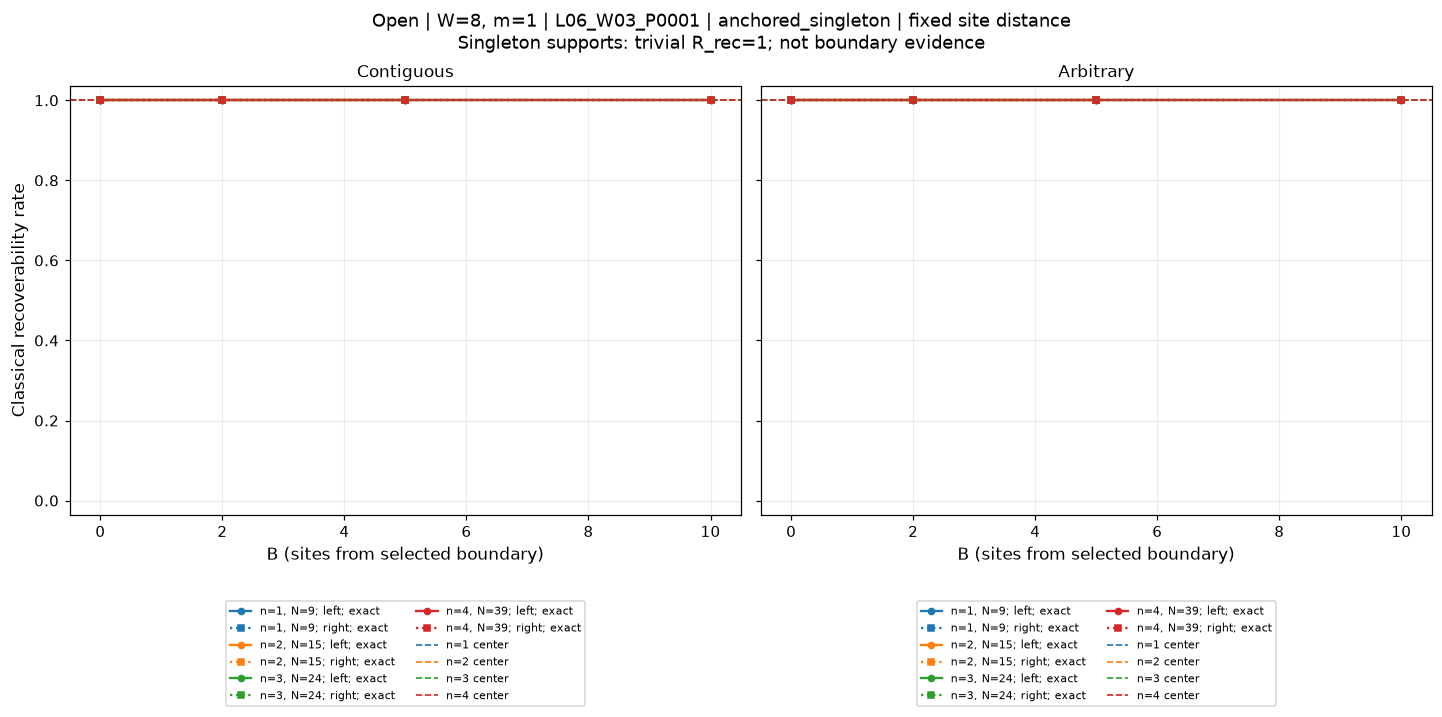

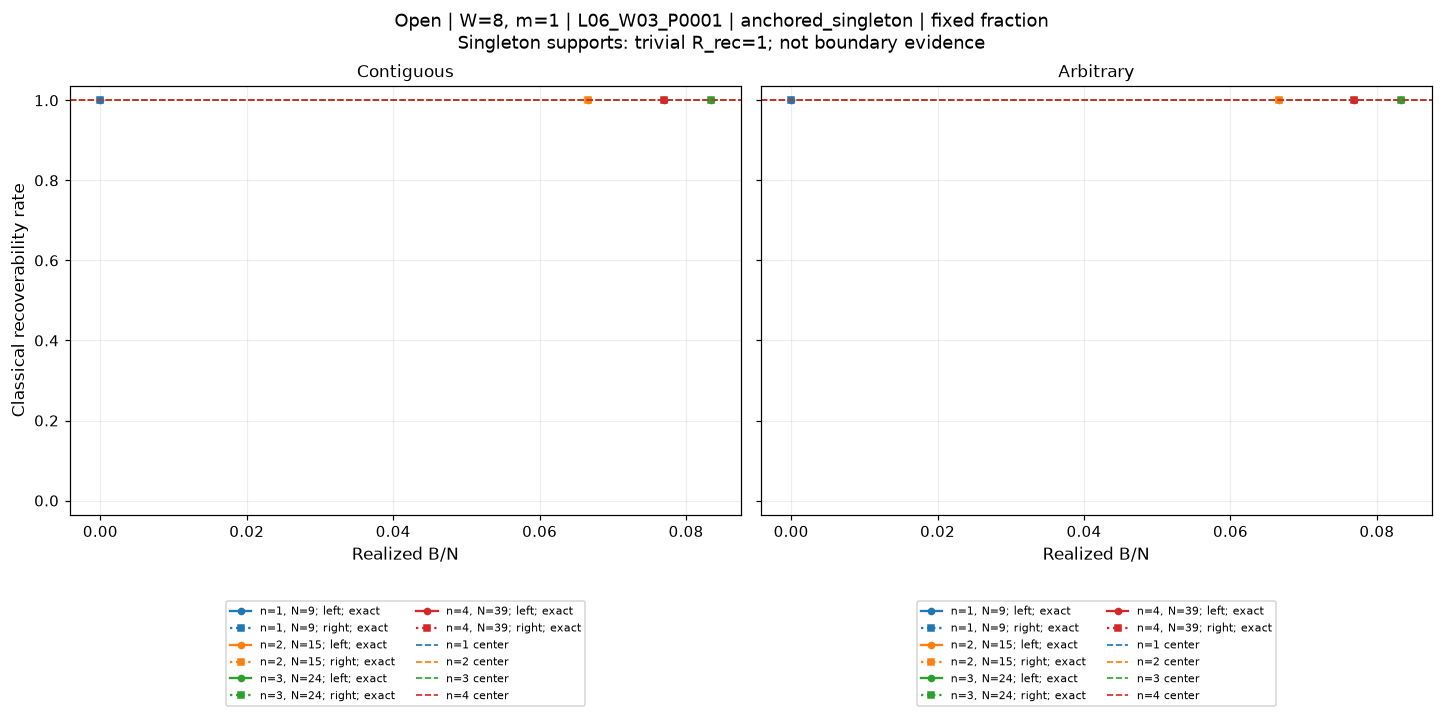

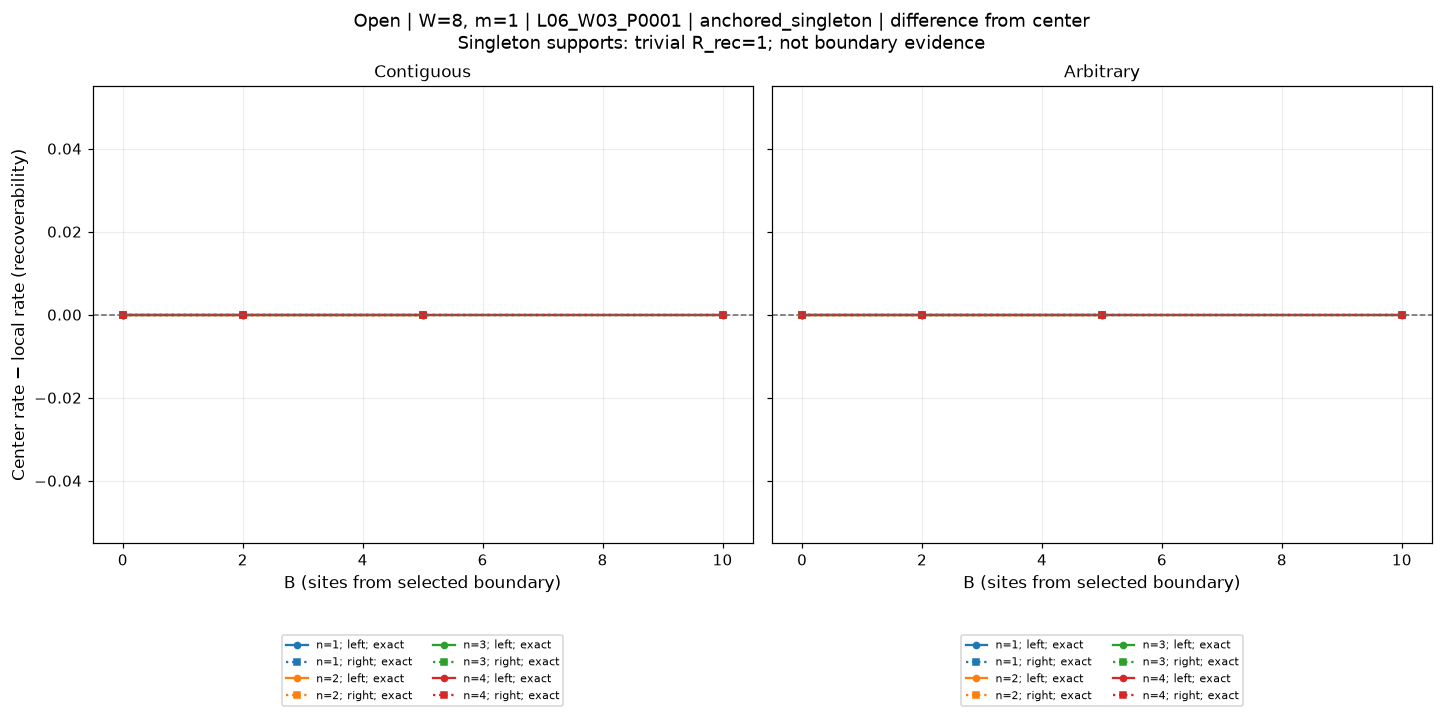

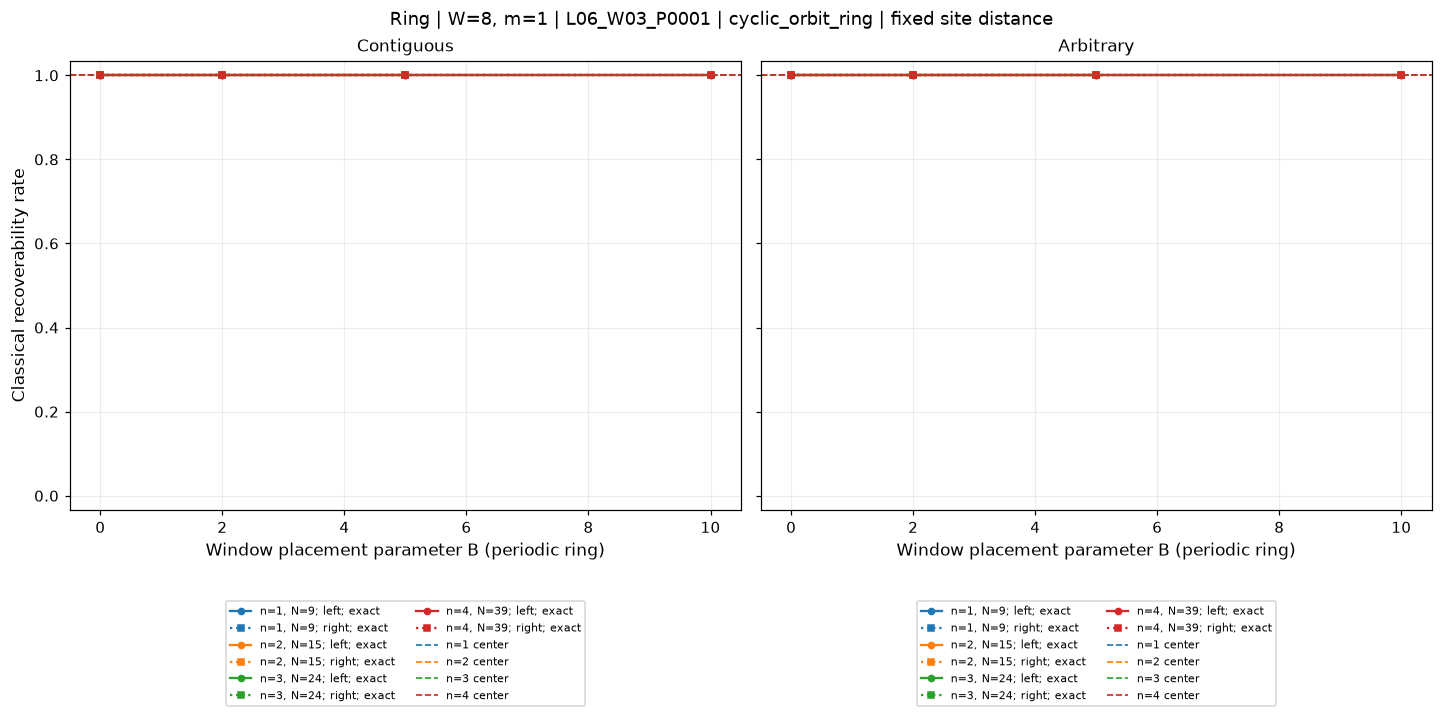

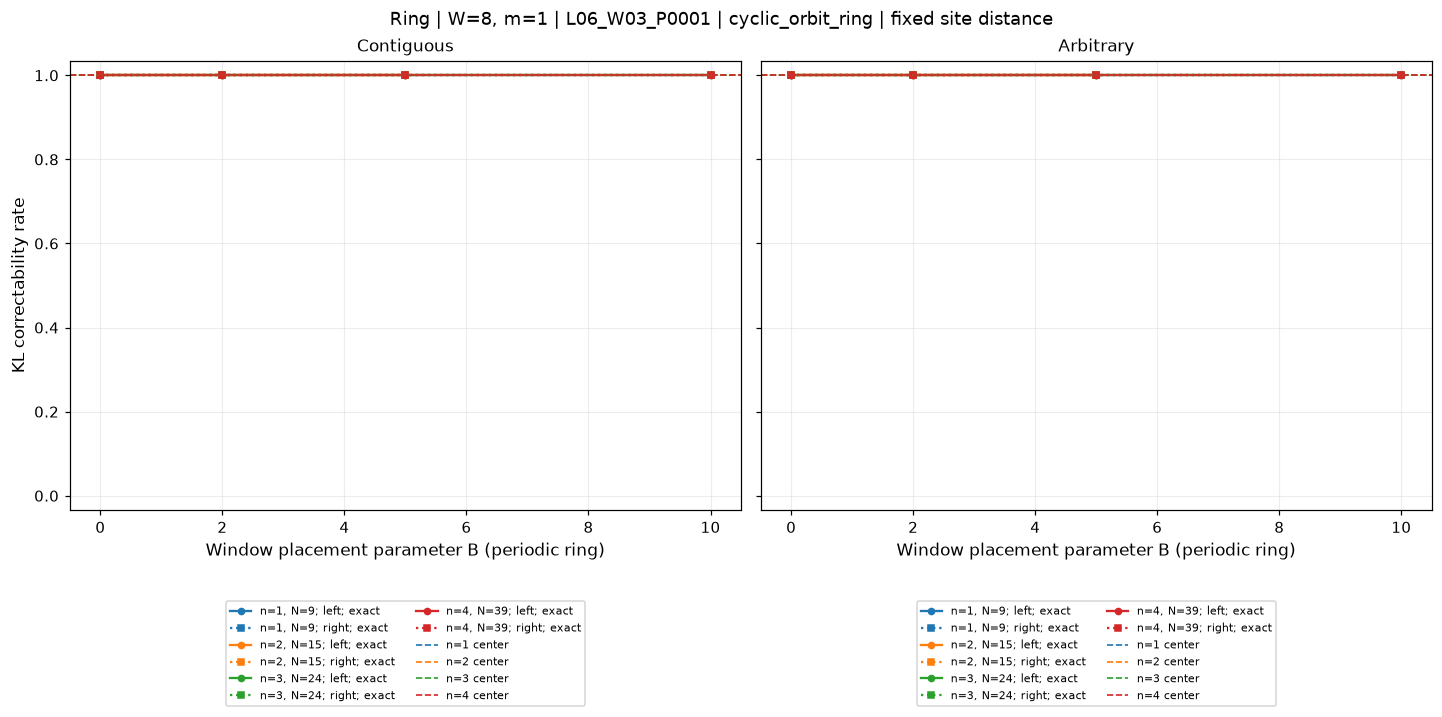

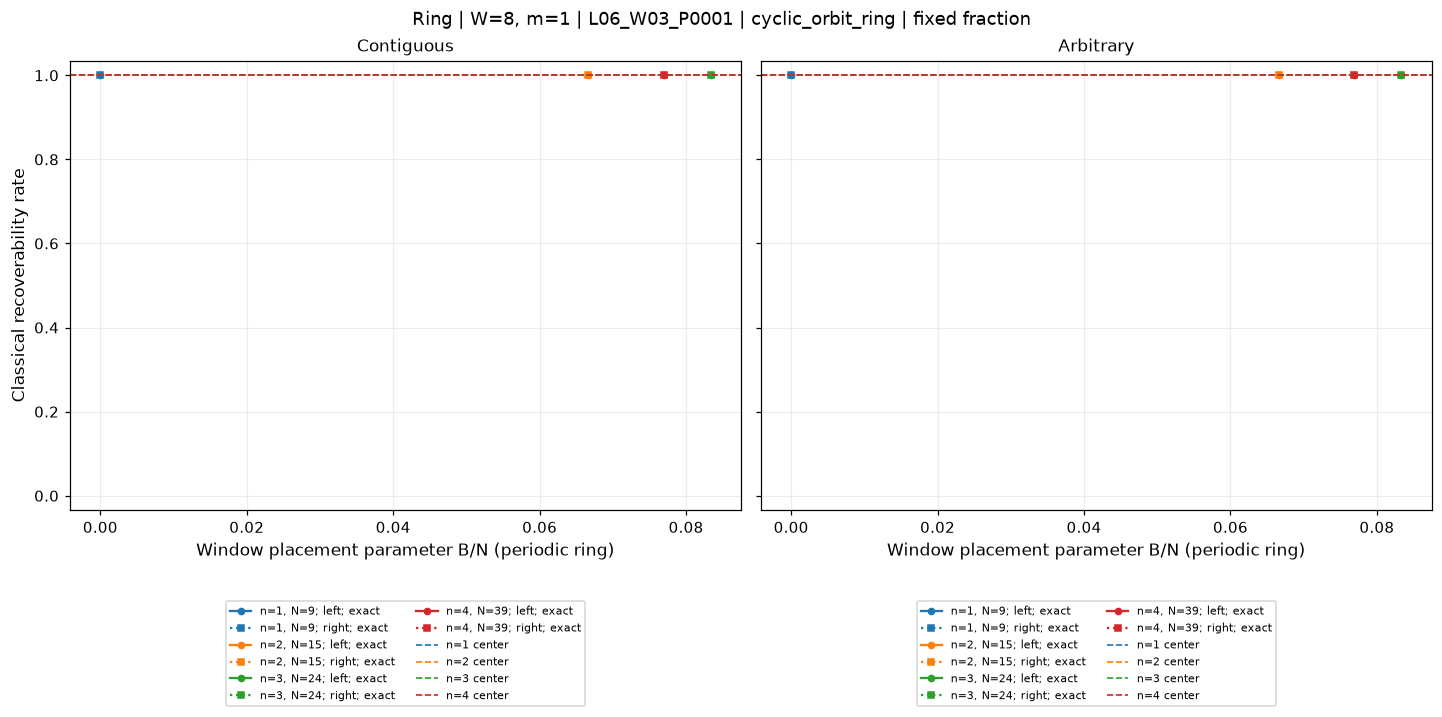

In [13]:
figures = []
if result is not None:
    figures = reporting.plot_boundary(summary_long_df, delta_df, threshold_df,
        output_dir=FIGURES_DIR if SAVE_FIGURES else None)
    for fig in figures[:6]:
        display(fig)
    for fig in figures:
        plt.close(fig)
    print(f"Figures generated: {len(figures)}; displayed first {min(6,len(figures))}")

## 16. 保存ファイル
`results/`（設定変更時は`OUTPUT_DIR`）に次を保存します。

- `boundary_distance_detail.csv`: 全試行。相対・絶対位置、geometry、両端距離、recoverability、KL条件。
- `boundary_distance_summary.csv`: 消失タイプを横に並べた指定形式。
- `boundary_distance_summary_long.csv`: 消失タイプ別の率・CI・分母・pattern digest。
- `boundary_distance_threshold.csv`: $B_\star$、持続しきい値、中央率、status。
- `boundary_distance_delta.csv`, `boundary_distance_mirror.csv`, `boundary_distance_paired.csv`。
- `geometry_open/`, `geometry_ring/`: detailと集計のgeometry別CSV。
- `run_metadata.json`, `run_status.json`, `open_candidate_sets.json`: 設定、モデル定義、実行状態、候補集合。
- `benchmark.csv`, `ring_translation_preflight.csv`, `ring_translation_sanity.csv`, `inflation_sizes.csv`, `window_plan.csv`。

図は`figures/`へ保存します。実行例は`example_results/`, `example_figures/`へ分けています。
`SAVE_RESULTS=False`ではCSV保存を行いません。`SAVE_FIGURES`は独立した設定です。

## 17. 結果まとめと研究上の問い
Q1（recoverabilityの境界距離依存）は指定された古典候補集合の下で評価します。
既定の単元集合では率が恒等的に1となるため、Q1・Q3・Q4・Q5を物理的に判定できません。
Q2（open KL）は量子状態の定義が入力されたときだけ評価できます。

非自明なモデルで距離依存が観測された場合も、有限鎖の局所構造、候補集合、左右の切断、反対側の端を併せて検討します。
有限個の$B,N$で平坦だったことだけから無限系への収束や境界効果の不存在を結論しません。
window内の任意消失と鎖全体に広がる任意消失も区別します。

finite-size scalingの$R(N)$と比較するときは、同じgeometry・候補集合・状態定義・$W,m$を確認します。
元のfinite ring QECCに物理的境界はないので、open補助モデルの結果をringの訂正性能の原因へ直接転用しません。

In [14]:
if result is not None:
    ring = summary_long_df[summary_long_df.geometry.eq("ring")]
    open_rows = summary_long_df[summary_long_df.geometry.eq("open")]
    print("Ring: all directly evaluated placement rates agree.")
    if len(open_rows) and open_rows.open_support_is_singleton.all():
        print("Open: singleton candidate classes give R_rec=1 identically; no boundary conclusion is identifiable.")
    if not ENABLE_OPEN_KL:
        print("Open KL: not evaluated (state definition absent).")
    print("B_star is restricted to the observed grid; center is a finite-chain reference.")
    if SAVE_RESULTS:
        print("CSV:", Path(OUTPUT_DIR).resolve())
    if SAVE_FIGURES:
        print("Figures:", Path(FIGURES_DIR).resolve())

Ring: all directly evaluated placement rates agree.
Open: singleton candidate classes give R_rec=1 identically; no boundary conclusion is identifiable.
Open KL: not evaluated (state definition absent).
B_star is restricted to the observed grid; center is a finite-chain reference.
CSV: /Users/ideryuito/Documents/Codex/2026-10-06/files-pasted-by-the-user-fibonacci-5/outputs/fibonacci_boundary_distance/example_results
Figures: /Users/ideryuito/Documents/Codex/2026-10-06/files-pasted-by-the-user-fibonacci-5/outputs/fibonacci_boundary_distance/example_figures


## 18. 検証と対象外
同梱の `test_boundary_distance.py` を `python -m unittest -v test_boundary_distance` で実行できます。
小さい系のdense部分トレースとの照合、巡回境界をまたぐ平行移動、自己衝突とクラス間衝突の区別、
同一sampling、skip条件、未計算KL、逐次保存を検証します。

mutual information、2点・3点相関、structure factor、seed最適化、Hamiltonian、2D modelは実装していません。